# **Clase 1. Carga y Limpieza de Datos**

## **1.  Definición del problema**

Se dispone de un dataset con información sociodemográfica de individuos (edad, ingreso, nivel educativo, profesión, entre otros), el cual presenta múltiples problemas de calidad como:

+ Datos faltantes
+ Registros duplicados
+ Inconsistencias en variables categóricas
+ Valores atípicos (outliers)
+ Datos erróneos (por ejemplo, ingresos negativos o edades irreales)


El problema consiste en:

Preparar y transformar el dataset para que sea apto para el entrenamiento de modelos de machine learning que apoyen la toma de decisiones.

## **2. Objetivo general**

Desarrollar un proceso completo de limpieza, transformación y preparación de datos que permita construir un dataset confiable y adecuado para aplicar técnicas de aprendizaje automático.

## **3. Objetivos específicos**

### **3.1 Identificar problemas de calidad de datos**

+ Detectar valores faltantes, duplicados e inconsistencias.

### **3.2 Realizar limpieza de datos**

+ Tratar valores nulos.
+ Eliminar o corregir registros erróneos.
+ Gestionar datos atípicos.

### **3.3 Estandarizar variables**

+ Unificar formatos de texto (mayúsculas/minúsculas).
+ Normalizar categorías (género, ciudad, estado civil).

### **3.4 Transformar variables**

+ Codificar variables categóricas (One-Hot, Ordinal).
+ Escalar variables numéricas.



### **3.5 Exportar datos**

## **4. Configuración del Entorno y Carga de Datos desde Google Drive**

En esta sección se importan las bibliotecas especializadas para análisis numérico, manipulación de datos, visualización y preprocesamiento de Machine Learning.

Se establece la conexión directa al archivo en Google Drive mediante su identificador (`FILE_ID`) para garantizar reproducibilidad en Google Colab.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Configuración gráfica y de visualización en Colab
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Conexión al archivo en Google Drive mediante enlace compartido público
FILE_ID = '1tabUckY1Y1FFlCsShjceSwngC8LEG5W-'
url = f'https://drive.google.com/uc?export=download&id={FILE_ID}'

# Carga de datos en un DataFrame de Pandas
df = pd.read_csv(url)
print(f'Conjunto de datos cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.')
df.head(10)

Conjunto de datos cargado con éxito: 30 filas y 12 columnas.


,ID,Nombre,Apellido,Edad,Ingreso,Genero,Ciudad,Profesion,Nivel_Educativo,Estado_Civil,Hijos,Email
0,1,Juan,Pérez,25.0,1200.0,MASCULINO,Bogotá,Ingeniero,Universitario,SOLTERO,0,juanp@gmail.com
1,2,Ana,Gómez,30.0,1500.0,Femenino,Medellín,Abogada,Especialización,Casada,1,ana.gomez@gmail.com
2,3,Carlos,Lopez,45.0,3000.0,MASCULINO,Cali,Medico,Maestría,CASADO,2,carlosl@gmail.com
3,4,María,Rodríguez,29.0,NaN,FEMENINO,Bogotá,Docente,Universitario,Soltera,0,maria@gmail.com
4,5,Pedro,Martinez,35.0,-2000.0,Masculino,bogotá,Comerciante,Bachiller,UNION LIBRE,3,pedro@gmail.com
5,6,Luisa,Hernandez,NaN,1800.0,FEMENINO,Cali,Ingeniera,Universitario,Soltera,0,luisa@gmail.com
6,7,Juan,Pérez,25.0,1200.0,MASCULINO,Bogotá,Ingeniero,Universitario,SOLTERO,0,juanp@gmail.com
7,8,Andres,Garcia,40.0,50000.0,MASCULINO,Medellín,Empresario,Maestría,Casado,2,andres@gmail.com
8,9,Sofía,Diaz,22.0,1100.0,Femenino,Cali,Estudiante,Universitario,Soltera,0,sofia@gmail.com
9,10,Camilo,torres,28.0,1300.0,MASCULINO,Bogotá,Ingeniero,Universitario,Soltero,0,camilo@gmail.com


## **5. Diagnóstico y Detección de Problemas de Calidad (Objetivo 3.1)**

Antes de transformar los datos, realizamos una auditoría completa para responder a las preguntas clave:
1. **Estructura y Tipos**: ¿Los tipos de datos (`dtypes`) corresponden a la naturaleza de cada variable?
2. **Duplicados**: ¿Existen registros repetidos que puedan sesgar el análisis o causar fuga de datos?
3. **Valores Nulos**: ¿Qué variables presentan datos faltantes y cuál es su proporción?
4. **Inconsistencias Categóricas**: ¿Existen variaciones tipográficas, errores ortográficos o mezclas de mayúsculas/minúsculas?
5. **Valores Erróneos y Outliers**: ¿Hay valores imposibles (edades inverosímiles, ingresos negativos) o valores atípicos extremos?

In [3]:
# 5.1 Estructura general y resumen estadístico
print('=== INFORMACIÓN ESTRUCTURAL (INFO) ===')
df.info()

print('\n=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS ===')
(df.describe())

=== INFORMACIÓN ESTRUCTURAL (INFO) ===
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               30 non-null     int64  
 1   Nombre           30 non-null     str    
 2   Apellido         30 non-null     str    
 3   Edad             28 non-null     float64
 4   Ingreso          28 non-null     float64
 5   Genero           30 non-null     str    
 6   Ciudad           30 non-null     str    
 7   Profesion        30 non-null     str    
 8   Nivel_Educativo  30 non-null     str    
 9   Estado_Civil     30 non-null     str    
 10  Hijos            30 non-null     int64  
 11  Email            30 non-null     str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.0 KB

=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS ===


,ID,Edad,Ingreso,Hijos
count,30.000000,28.000000,28.000000,30.000000
mean,15.500000,38.285714,3200.000000,0.966667
std,8.803408,32.889103,9316.164765,1.217214
min,1.000000,22.000000,-2000.000000,0.000000
25%,8.250000,25.750000,1200.000000,0.000000
50%,15.500000,29.500000,1325.000000,0.000000
75%,22.750000,37.250000,1625.000000,2.000000
max,30.000000,200.000000,50000.000000,4.000000


In [4]:
# 5.2 Detección de Registros Duplicados
duplicados_completos = df.duplicated().sum()
print(f'Duplicados exactos (todas las columnas incluyendo ID): {duplicados_completos}')

# Evaluamos duplicados por identidad (clave única natural: Email)
duplicados_email = df[df.duplicated(subset=['Email'], keep=False)].sort_values(by='Email')
print(f'Total de registros asociados a Emails duplicados: {len(duplicados_email)}')
(duplicados_email[['ID', 'Nombre', 'Apellido', 'Edad', 'Ingreso', 'Email', 'Ciudad', 'Profesion']])

Duplicados exactos (todas las columnas incluyendo ID): 0
Total de registros asociados a Emails duplicados: 6


,ID,Nombre,Apellido,Edad,Ingreso,Email,Ciudad,Profesion
0,1,Juan,Pérez,25.0,1200.0,juanp@gmail.com,Bogotá,Ingeniero
6,7,Juan,Pérez,25.0,1200.0,juanp@gmail.com,Bogotá,Ingeniero
19,20,Juan,Perez,25.0,1200.0,juanp@gmail.com,Bogotá,Ingeniero
29,30,Juan,Pérez,25.0,1200.0,juanp@gmail.com,Bogotá,Ingeniero
4,5,Pedro,Martinez,35.0,-2000.0,pedro@gmail.com,bogotá,Comerciante
20,21,Pedro,Martinez,35.0,-1500.0,pedro@gmail.com,bogota,Comerciante


In [5]:
# 5.3 Detección de Valores Faltantes (Nulos / NaN)
resumen_nulos = pd.DataFrame({
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print('=== RESUMEN DE CAMPOS CON VALORES NULOS ===')
(resumen_nulos[resumen_nulos['Valores Nulos'] > 0])

print('\nRegistros específicos con valores nulos:')
(df[df.isnull().any(axis=1)])

=== RESUMEN DE CAMPOS CON VALORES NULOS ===

Registros específicos con valores nulos:


,ID,Nombre,Apellido,Edad,Ingreso,Genero,Ciudad,Profesion,Nivel_Educativo,Estado_Civil,Hijos,Email
3,4,María,Rodríguez,29.0,NaN,FEMENINO,Bogotá,Docente,Universitario,Soltera,0,maria@gmail.com
5,6,Luisa,Hernandez,NaN,1800.0,FEMENINO,Cali,Ingeniera,Universitario,Soltera,0,luisa@gmail.com
13,14,José,Suarez,33.0,NaN,MASCULINO,Medellín,Ingeniero,Especialización,Casado,1,jose@gmail.com
17,18,Felipe,Rojas,NaN,1450.0,MASCULINO,Medellín,Ingeniero,Universitario,Soltero,0,felipe@gmail.com


In [6]:
# 5.4 Inconsistencias en Variables Categóricas
cat_cols = ['Genero', 'Ciudad', 'Estado_Civil', 'Profesion', 'Nivel_Educativo']
print('=== VALORES ÚNICOS Y FRECUENCIAS POR VARIABLE CATEGÓRICA ===')
for col in cat_cols:
    print(f'\n--- Columna: {col} ({df[col].nunique()} valores únicos) ---')
    print(df[col].value_counts(dropna=False).to_dict())

=== VALORES ÚNICOS Y FRECUENCIAS POR VARIABLE CATEGÓRICA ===

--- Columna: Genero (4 valores únicos) ---
{'MASCULINO': 16, 'Femenino': 8, 'FEMENINO': 5, 'Masculino': 1}

--- Columna: Ciudad (5 valores únicos) ---
{'Bogotá': 11, 'Cali': 9, 'Medellín': 8, 'bogotá': 1, 'bogota': 1}

--- Columna: Estado_Civil (8 valores únicos) ---
{'Soltera': 10, 'Casado': 8, 'SOLTERO': 4, 'Casada': 3, 'Soltero': 2, 'CASADO': 1, 'UNION LIBRE': 1, 'Union libre': 1}

--- Columna: Profesion (12 valores únicos) ---
{'Ingeniero': 8, 'Docente': 3, 'Estudiante': 3, 'Abogada': 2, 'Comerciante': 2, 'Empresario': 2, 'Psicologa': 2, 'Contador': 2, 'Diseñadora': 2, 'Administrador': 2, 'Medico': 1, 'Ingeniera': 1}

--- Columna: Nivel_Educativo (4 valores únicos) ---
{'Universitario': 18, 'Especialización': 6, 'Maestría': 4, 'Bachiller': 2}


In [7]:
# 5.5 Detección de Valores Erróneos y Outliers
print('--- 1. Edades biológicamente erróneas (> 100 años) ---')
(df[df['Edad'] > 100][['ID', 'Nombre', 'Apellido', 'Edad', 'Profesion']])

print('\n--- 2. Ingresos negativos o en cero ---')
(df[df['Ingreso'] <= 0][['ID', 'Nombre', 'Apellido', 'Ingreso', 'Profesion']])

# 5.6 Análisis de Outliers en Ingreso mediante Rango Intercuartílico (IQR)
q1 = df['Ingreso'].quantile(0.25)
q3 = df['Ingreso'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f'\n--- 3. Límite superior IQR para Ingreso: ${limite_superior:,.2f} ---')
outliers_ingreso = df[df['Ingreso'] > limite_superior]
print(f'Total de registros que superan el límite superior IQR: {len(outliers_ingreso)}')
(outliers_ingreso[['ID', 'Nombre', 'Apellido', 'Ingreso', 'Profesion', 'Nivel_Educativo']])

--- 1. Edades biológicamente erróneas (> 100 años) ---

--- 2. Ingresos negativos o en cero ---

--- 3. Límite superior IQR para Ingreso: $2,262.50 ---
Total de registros que superan el límite superior IQR: 4


,ID,Nombre,Apellido,Ingreso,Profesion,Nivel_Educativo
2,3,Carlos,Lopez,3000.0,Medico,Maestría
7,8,Andres,Garcia,50000.0,Empresario,Maestría
14,15,Miguel,Ortega,8000.0,Administrador,Maestría
27,28,Ricardo,Acosta,3000.0,Empresario,Maestría


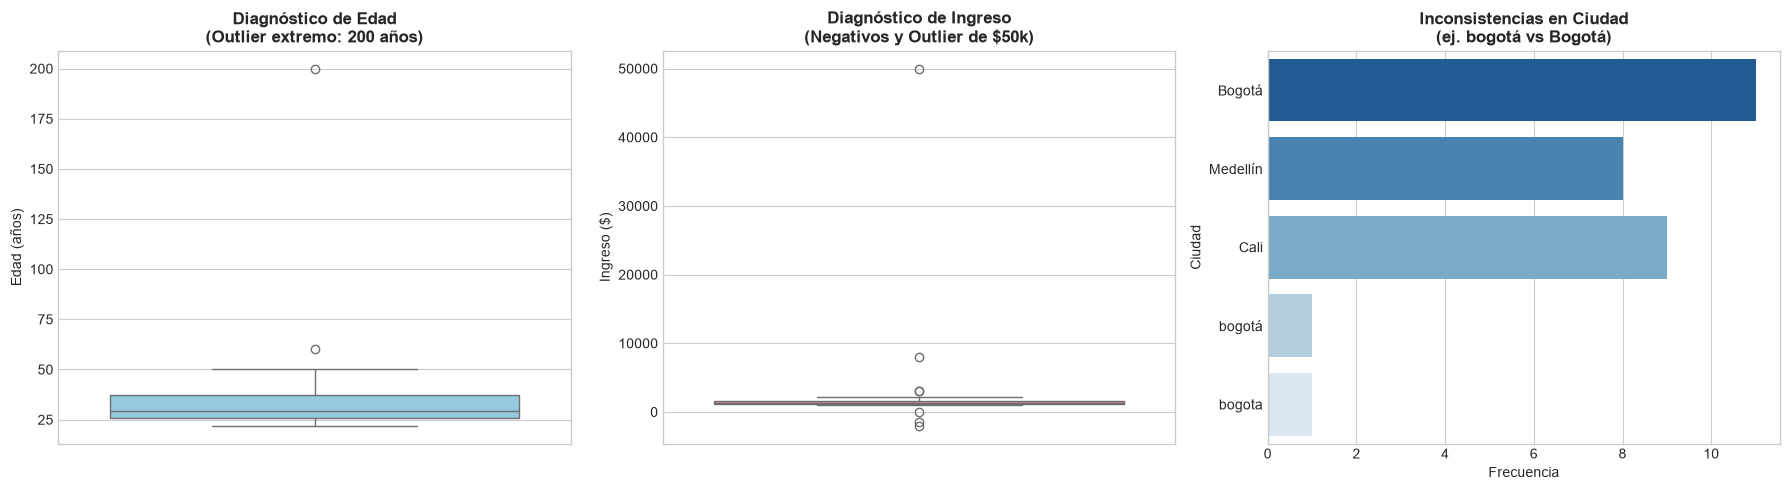

In [8]:
# 5.7 Visualización Gráfica del Diagnóstico Inicial
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot de Edad
sns.boxplot(y=df['Edad'], ax=axes[0], color='skyblue')
axes[0].set_title('Diagnóstico de Edad\n(Outlier extremo: 200 años)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Edad (años)')

# Boxplot de Ingreso
sns.boxplot(y=df['Ingreso'], ax=axes[1], color='lightcoral')
axes[1].set_title('Diagnóstico de Ingreso\n(Negativos y Outlier de $50k)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Ingreso ($)')

# Frecuencia de Ciudades con discrepancias
sns.countplot(y=df['Ciudad'], ax=axes[2], hue=df['Ciudad'], palette='Blues_r', legend=False)
axes[2].set_title('Inconsistencias en Ciudad\n(ej. bogotá vs Bogotá)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Frecuencia')

plt.tight_layout()
plt.show()

## **6. Estandarización de Variables Categóricas y de Texto (Objetivo 3.3)**

La normalización textual es necesaria antes de consolidar el dataset y eliminar duplicados:
+ **Espacios en blanco y mayúsculas/minúsculas**: limpieza con `.strip()` y capitalización uniforme.
+ **Género**: Unificación a formato binario estandarizado (*Masculino* y *Femenino*).
+ **Ciudad**: Corrección ortográfica y de tildes (*Bogotá*, *Medellín*, *Cali*).
+ **Estado Civil**: Eliminación del sesgo de flexión de género gramatical (*Soltero/Soltera* -> *Soltero*, *Casado/Casada* -> *Casado*, *Unión Libre*).
+ **Profesión**: Homogeneización de denominaciones (*Ingeniera* -> *Ingeniero*, tilde en *Psicóloga*).

In [9]:
# Creamos una copia de trabajo para no alterar el dataset original crudo
df_clean = df.copy()

# 6.1 Limpieza general de cadenas de texto
text_cols = ['Nombre', 'Apellido', 'Ciudad', 'Profesion', 'Nivel_Educativo', 'Estado_Civil', 'Email']
for col in text_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

df_clean['Email'] = df_clean['Email'].str.lower()
df_clean['Nombre'] = df_clean['Nombre'].str.capitalize()
df_clean['Apellido'] = df_clean['Apellido'].str.capitalize()

# 6.2 Normalización de Género
df_clean['Genero'] = df_clean['Genero'].str.capitalize()

# 6.3 Normalización de Ciudad
map_ciudad = {
    'bogota': 'Bogotá',
    'bogotá': 'Bogotá',
    'medellin': 'Medellín',
    'medellín': 'Medellín',
    'cali': 'Cali'
}
df_clean['Ciudad'] = df_clean['Ciudad'].str.lower().map(map_ciudad)

# 6.4 Normalización de Estado Civil
map_estado_civil = {
    'soltero': 'Soltero',
    'soltera': 'Soltero',
    'casado': 'Casado',
    'casada': 'Casado',
    'union libre': 'Unión Libre',
    'unión libre': 'Unión Libre'
}
df_clean['Estado_Civil'] = df_clean['Estado_Civil'].str.lower().map(map_estado_civil)

# 6.5 Normalización de Profesión
map_profesion = {
    'ingeniera': 'Ingeniero',
    'psicologa': 'Psicóloga'
}
df_clean['Profesion'] = df_clean['Profesion'].map(lambda x: map_profesion.get(x.lower(), x.capitalize()))

print('=== VALORES ÚNICOS TRAS LA ESTANDARIZACIÓN ===')
for col in ['Genero', 'Ciudad', 'Estado_Civil', 'Profesion']:
    print(f'- {col}: {df_clean[col].unique().tolist()}')

=== VALORES ÚNICOS TRAS LA ESTANDARIZACIÓN ===
- Genero: ['Masculino', 'Femenino']
- Ciudad: ['Bogotá', 'Medellín', 'Cali']
- Estado_Civil: ['Soltero', 'Casado', 'Unión Libre']
- Profesion: ['Ingeniero', 'Abogada', 'Medico', 'Docente', 'Comerciante', 'Empresario', 'Estudiante', 'Psicóloga', 'Contador', 'Diseñadora', 'Administrador']


## **7. Limpieza de Datos (Objetivo 3.2)**

En esta etapa se abordan los problemas sustantivos identificados en el diagnóstico:
1. **Deduplicación**: Eliminación de registros repetidos utilizando la clave natural `Email`.
2. **Corrección de valores erróneos**: Transformación de ingresos negativos mediante valor absoluto (`abs()`) y sustitución de la edad de 200 años por `NaN`.
3. **Tratamiento de Outliers**: Aplicación de la técnica de *Winsorización / Capping* sobre el ingreso extremo ($50,000) fijándolo al límite superior del rango intercuartílico (IQR), reteniendo la información sin distorsionar modelos futuros.
4. **Imputación de Valores Faltantes**: Imputación de `Edad` mediante la mediana global, e imputación de `Ingreso` mediante la mediana agrupada por `Nivel_Educativo`.

In [10]:
# 7.1 Eliminación de Registros Duplicados
n_antes = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['Email'], keep='first').reset_index(drop=True)
n_despues = len(df_clean)

print(f'Filas antes de deduplicar: {n_antes}')
print(f'Filas después de deduplicar: {n_despues}')
print(f'Total de registros duplicados eliminados: {n_antes - n_despues}')

Filas antes de deduplicar: 30
Filas después de deduplicar: 26
Total de registros duplicados eliminados: 4


In [11]:
# 7.2 Corrección de Valores Erróneos y Outliers
# Ingresos negativos: error de signo en captura -> se toma el valor absoluto abs()
df_clean['Ingreso'] = df_clean['Ingreso'].apply(lambda x: abs(x) if pd.notnull(x) else np.nan)

# Edades biológicamente inverosímiles (> 100 años): se reemplazan con NaN para su imputación
df_clean.loc[df_clean['Edad'] > 100, 'Edad'] = np.nan

# 7.3 Gestión de Outliers en Ingreso (Winsorización / Capping)
q1_clean = df_clean['Ingreso'].dropna().quantile(0.25)
q3_clean = df_clean['Ingreso'].dropna().quantile(0.75)
iqr_clean = q3_clean - q1_clean
lim_sup_clean = q3_clean + 1.5 * iqr_clean
print(f'Límite superior IQR para Ingreso: ${lim_sup_clean:,.2f}')

# Creamos Ingreso_Ajustado para evitar distorsiones en modelos de Machine Learning
df_clean['Ingreso_Ajustado'] = df_clean['Ingreso'].clip(upper=lim_sup_clean)
print(f'Ingreso máximo antes del capping: ${df_clean["Ingreso"].max():,.2f}')
print(f'Ingreso máximo después del capping: ${df_clean["Ingreso_Ajustado"].max():,.2f}')

Límite superior IQR para Ingreso: $2,750.00
Ingreso máximo antes del capping: $50,000.00
Ingreso máximo después del capping: $2,750.00


In [12]:
# 7.4 Imputación Estadística de Valores Nulos
print('Conteo de nulos antes de imputar:')
print(df_clean[['Edad', 'Ingreso', 'Ingreso_Ajustado']].isnull().sum())

# Imputación de Edad con la mediana global
mediana_edad = df_clean['Edad'].median()
df_clean['Edad'] = df_clean['Edad'].fillna(mediana_edad)

# Imputación de Ingreso con la mediana agrupada por Nivel Educativo
mediana_ingreso_edu = df_clean.groupby('Nivel_Educativo')['Ingreso_Ajustado'].transform('median')
df_clean['Ingreso_Ajustado'] = df_clean['Ingreso_Ajustado'].fillna(mediana_ingreso_edu).fillna(df_clean['Ingreso_Ajustado'].median())
df_clean['Ingreso'] = df_clean['Ingreso'].fillna(df_clean.groupby('Nivel_Educativo')['Ingreso'].transform('median'))

print('\nConteo de nulos tras la imputación:')
print(f'Total de valores nulos en el dataset: {df_clean.isnull().sum().sum()}')
(df_clean.head())

Conteo de nulos antes de imputar:
Edad                3
Ingreso             2
Ingreso_Ajustado    2
dtype: int64

Conteo de nulos tras la imputación:
Total de valores nulos en el dataset: 0


,ID,Nombre,Apellido,Edad,Ingreso,Genero,Ciudad,Profesion,Nivel_Educativo,Estado_Civil,Hijos,Email,Ingreso_Ajustado
0,1,Juan,Pérez,25.0,1200.0,Masculino,Bogotá,Ingeniero,Universitario,Soltero,0,juanp@gmail.com,1200.0
1,2,Ana,Gómez,30.0,1500.0,Femenino,Medellín,Abogada,Especialización,Casado,1,ana.gomez@gmail.com,1500.0
2,3,Carlos,Lopez,45.0,3000.0,Masculino,Cali,Medico,Maestría,Casado,2,carlosl@gmail.com,2750.0
3,4,María,Rodríguez,29.0,1275.0,Femenino,Bogotá,Docente,Universitario,Soltero,0,maria@gmail.com,1275.0
4,5,Pedro,Martinez,35.0,2000.0,Masculino,Bogotá,Comerciante,Bachiller,Unión Libre,3,pedro@gmail.com,2000.0


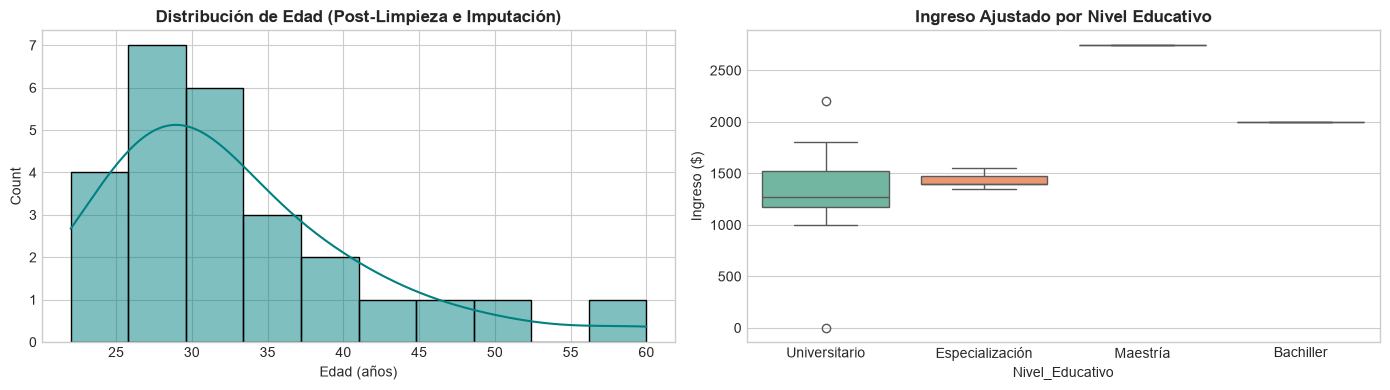

In [13]:
# 7.5 Visualización Gráfica Post-Limpieza
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_clean['Edad'], kde=True, ax=axes[0], color='teal', bins=10)
axes[0].set_title('Distribución de Edad (Post-Limpieza e Imputación)', fontweight='bold')
axes[0].set_xlabel('Edad (años)')

sns.boxplot(x=df_clean['Nivel_Educativo'], y=df_clean['Ingreso_Ajustado'], ax=axes[1], hue=df_clean['Nivel_Educativo'], palette='Set2', legend=False)
axes[1].set_title('Ingreso Ajustado por Nivel Educativo', fontweight='bold')
axes[1].set_ylabel('Ingreso ($)')

plt.tight_layout()
plt.show()

## **8. Transformación y Preparación de Variables para Machine Learning (Objetivo 3.4)**

Para que los modelos de Machine Learning puedan procesar la información de forma matemáticamente consistente, realizamos:
1. **Exclusión de Identificadores**: `ID`, `Nombre`, `Apellido` y `Email` no aportan valor predictivo y generan sobreajuste o memorización.
2. **Codificación Ordinal**: Para `Nivel_Educativo`, preservando la progresión intrínseca: *Bachiller (0) < Universitario (1) < Especialización (2) < Maestría (3)*.
3. **Codificación One-Hot (Nominal)**: Para `Genero`, `Ciudad`, `Estado_Civil` y `Profesion`, aplicando `drop_first=True` para evitar la trampa de las variables ficticias (multicolinealidad perfecta).
4. **Escalado Numérico**: Aplicamos `StandardScaler` (útil para regresiones, SVM, redes neuronales) y `MinMaxScaler` (útil para algoritmos de distancias como KNN o K-Means).

In [ ]:
# 8.1 Selección de Variables predictoras
df_ml = df_clean.drop(columns=['ID', 'Nombre', 'Apellido', 'Email', 'Ingreso']).copy()

# 8.2 Codificación Ordinal para Nivel_Educativo
map_orden_educacion = {
    'Bachiller': 0,
    'Universitario': 1,
    'Especialización': 2,
    'Maestría': 3
}
df_ml['Nivel_Educativo_Cod'] = df_ml['Nivel_Educativo'].map(map_orden_educacion)
df_ml = df_ml.drop(columns=['Nivel_Educativo'])

# 8.3 Codificación One-Hot para variables nominales
nominales = ['Genero', 'Ciudad', 'Estado_Civil', 'Profesion']
df_ml = pd.get_dummies(df_ml, columns=nominales, drop_first=True, dtype=int)

print(f'Dimensiones de la matriz de características (Features): {df_ml.shape[0]} filas, {df_ml.shape[1]} columnas.')
(df_ml.head())

Dimensiones de la matriz de características (Features): 26 filas, 19 columnas.


,Edad,Hijos,Ingreso_Ajustado,Nivel_Educativo_Cod,Genero_Masculino,Ciudad_Cali,Ciudad_Medellín,Estado_Civil_Soltero,Estado_Civil_Unión Libre,Profesion_Administrador,Profesion_Comerciante,Profesion_Contador,Profesion_Diseñadora,Profesion_Docente,Profesion_Empresario,Profesion_Estudiante,Profesion_Ingeniero,Profesion_Medico,Profesion_Psicóloga
0,25.0,0,1200.0,1,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0
1,30.0,1,1500.0,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2,45.0,2,2750.0,3,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0
3,29.0,0,1275.0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0
4,35.0,3,2000.0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0


In [15]:
# 8.4 Escalado de Variables Numéricas
num_features = ['Edad', 'Ingreso_Ajustado', 'Hijos']

# Opción A: Estandarización (StandardScaler: z = (x - u) / s)
scaler_std = StandardScaler()
df_ml_std = df_ml.copy()
df_ml_std[[f'{col}_std' for col in num_features]] = scaler_std.fit_transform(df_ml[num_features])

# Opción B: Normalización Min-Max (MinMaxScaler: rango [0, 1])
scaler_mm = MinMaxScaler()
df_ml_mm = df_ml.copy()
df_ml_mm[[f'{col}_minmax' for col in num_features]] = scaler_mm.fit_transform(df_ml[num_features])

print('=== MUESTRA DEL DATASET ESCALADO CON STANDARDSCALER ===')
(df_ml_std.head())

=== MUESTRA DEL DATASET ESCALADO CON STANDARDSCALER ===


,Edad,Hijos,Ingreso_Ajustado,Nivel_Educativo_Cod,Genero_Masculino,Ciudad_Cali,Ciudad_Medellín,Estado_Civil_Soltero,Estado_Civil_Unión Libre,Profesion_Administrador,Profesion_Comerciante,Profesion_Contador,Profesion_Diseñadora,Profesion_Docente,Profesion_Empresario,Profesion_Estudiante,Profesion_Ingeniero,Profesion_Medico,Profesion_Psicóloga,Edad_std,Ingreso_Ajustado_std,Hijos_std
0,25.0,0,1200.0,1,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,-0.902073,-0.614529,-0.849837
1,30.0,1,1500.0,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,-0.321531,-0.133995,0.000000
2,45.0,2,2750.0,3,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1.420096,1.868231,0.849837
3,29.0,0,1275.0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,-0.437640,-0.494396,-0.849837
4,35.0,3,2000.0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0.259011,0.666895,1.699673


## **9. Exportación de Datos (Objetivo 3.5) y Tabla Comparativa**

Se exportan dos artefactos analíticos:
1. `dataset_limpio_descriptivo.csv`: Datos limpios, deduplicados e imputados, ideales para reportería, tableros de BI (Power BI/Tableau) y análisis de negocio.
2. `dataset_preparado_ml.csv`: Matriz 100% numérica, codificada y escalada, lista para entrenamiento de algoritmos de Machine Learning.

In [16]:
# 9.1 Exportación a archivos CSV
df_clean.to_csv('dataset_limpio_descriptivo.csv', index=False)
df_ml_std.to_csv('dataset_preparado_ml.csv', index=False)

print(' Archivos exportados con éxito:')
print('1. dataset_limpio_descriptivo.csv -> Para análisis exploratorio y tableros de negocio.')
print('2. dataset_preparado_ml.csv -> Para modelos predictivos de Machine Learning.')

 Archivos exportados con éxito:
1. dataset_limpio_descriptivo.csv -> Para análisis exploratorio y tableros de negocio.
2. dataset_preparado_ml.csv -> Para modelos predictivos de Machine Learning.


In [17]:
# 9.2 Tabla Comparativa de Calidad: Estado Inicial vs. Estado Final
resumen_comparativo = pd.DataFrame({
    'Métrica de Calidad': [
        'Total de filas',
        'Registros duplicados (por Email)',
        'Valores nulos en Edad',
        'Valores nulos en Ingreso',
        'Ingresos negativos (erróneos)',
        'Edades biológicamente erróneas (> 100)',
        'Outliers extremos de Ingreso (> $10k)',
        'Variantes ortográficas en Ciudad',
        'Variantes tipográficas en Género',
        'Estado de preparación para ML'
    ],
    'Dataset Original (Crudo)': [
        len(df),
        df.duplicated(subset=['Email']).sum(),
        df['Edad'].isnull().sum(),
        df['Ingreso'].isnull().sum(),
        (df['Ingreso'] < 0).sum(),
        (df['Edad'] > 100).sum(),
        (df['Ingreso'] > 10000).sum(),
        df['Ciudad'].nunique(),
        df['Genero'].nunique(),
        'No apto (Texto, nulos, errores, multiescala)'
    ],
    'Dataset Final (Procesado)': [
        len(df_clean),
        0,
        0,
        0,
        0,
        0,
        0,
        df_clean['Ciudad'].nunique(),
        df_clean['Genero'].nunique(),
        'Totalmente apto (Numérico, codificado y escalado)'
    ]
})

(resumen_comparativo)

,Métrica de Calidad,Dataset Original (Crudo),Dataset Final (Procesado)
0,Total de filas,30,26
1,Registros duplicados (por Email),4,0
2,Valores nulos en Edad,2,0
3,Valores nulos en Ingreso,2,0
4,Ingresos negativos (erróneos),2,0
5,Edades biológicamente erróneas (> 100),1,0
6,Outliers extremos de Ingreso (> $10k),1,0
7,Variantes ortográficas en Ciudad,5,3
8,Variantes tipográficas en Género,4,2
9,Estado de preparación para ML,"No apto (Texto, nulos, errores, multiescala)","Totalmente apto (Numérico, codificado y escalado)"


## **10. Conclusiones y Toma de Decisiones**

1. **Consistencia de la Información**: La deduplicación por clave de negocio (`Email`) redujo el tamaño muestral de 30 a 26 registros únicos, evitando que duplicados redundantes generen sesgos y sobreajuste en modelos supervisados.
2. **Mitigación de Errores Numéricos**: Se solventaron errores de captura de signos negativos en ingresos (`abs()`), la distorsión biológica de edad (200 años a `NaN`) y la presencia del outlier extremo de $50,000 mediante técnica de *capping* al límite superior del rango intercuartílico (IQR = $2,750).
3. **Estrategia de Imputación Fina**: En lugar de utilizar una media global sensible a distorsiones, se empleó la mediana agrupada por nivel educativo para ingresos y la mediana global para edad, manteniendo la coherencia socioeconómica de los perfiles.
4. **Aptitud para Modelos de Machine Learning**: Con la codificación ordinal para variables jerárquicas (`Nivel_Educativo`), One-Hot Encoding sin multicolinealidad (`drop_first=True`) para atributos nominales y estandarización numérica (`StandardScaler`/`MinMaxScaler`), el conjunto de datos queda completamente preparado para modelos predictivos y de toma de decisiones empresariales.